In [4]:
# Step 1 — Import libraries and load cleaned data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [5]:
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [6]:
data_path = Path("/Users/sourav/Desktop/Projects/Practise/credit-card-default-prediction/data/processed/credit_card_cleaned.csv")
df = pd.read_csv(data_path)

print("Dataset shape: ", df.shape)
display(df.head())

print("\n Target distribution : ")
print(df["default"].value_counts())

Dataset shape:  (30000, 25)


,ID,LIMIT_BAL,SEX,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default,EDUCATION,MARRIAGE
0,1,20000.0,2,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1,2,1
1,2,120000.0,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1,2,2
2,3,90000.0,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0,2,2
3,4,50000.0,2,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0,2,1
4,5,50000.0,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0,2,1



 Target distribution : 
default
0    23364
1     6636
Name: count, dtype: int64


In [7]:
# EDA Part A — Analyse the target variable
# Step 2 — Calculate the default rate

default_counts = df["default"].value_counts().sort_index()
default_rate = df["default"].mean() * 100

print("Dafault rate: ", round(default_rate, 2), "%")
print(default_counts)

Dafault rate:  22.12 %
default
0    23364
1     6636
Name: count, dtype: int64


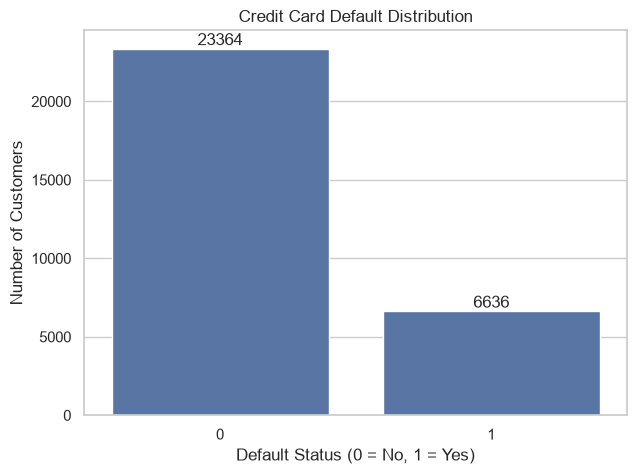

In [8]:
plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x="default",
    order=[0, 1]
)

plt.title("Credit Card Default Distribution")
plt.xlabel("Default Status (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [9]:
# EDA Part B — Credit limit and default risk
# Step 4 — Compare credit limits by default status

summary = (df.groupby("default")["LIMIT_BAL"].agg(
    ["count", "mean", "median", "std"]
).round(2))

display(summary)

,count,mean,median,std
default,,,,
0,23364,178099.73,150000.0,131628.36
1,6636,130109.66,90000.0,115378.54


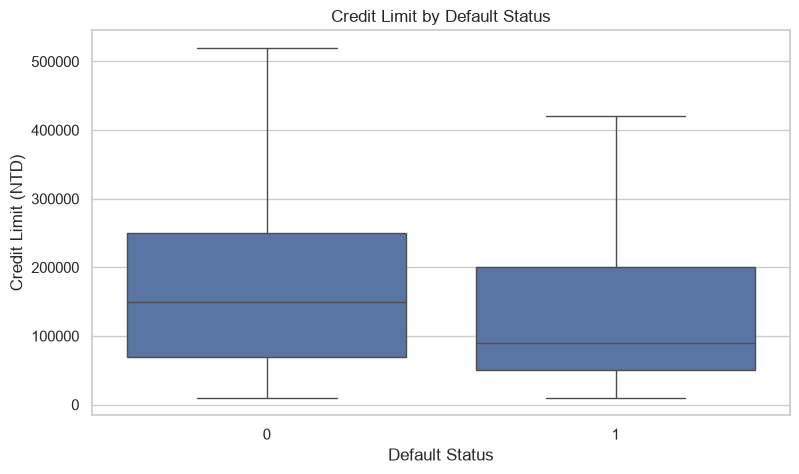

In [10]:
# create a boxplot:
plt.figure(figsize=(9,5))

sns.boxplot(
    data=df,
    x="default",
    y="LIMIT_BAL",
    showfliers=False
)

plt.title("Credit Limit by Default Status")
plt.xlabel("Default Status")
plt.ylabel("Credit Limit (NTD)")

plt.show()

In [11]:
# Step 5 — Calculate default rate by credit limit band
df["credit_limit_band"] = pd.cut(
    df["LIMIT_BAL"],
    bins=[0, 50000, 100000, 200000, 500000, np.inf],
    labels=[
        "<=50k",
        "50k-100k",
        "100k-200k",
        "200k-500k",
        ">500k"
    ],
    include_lowest=True
)
limit_risk=(
    df.groupby("credit_limit_band", observed = True)
    .agg(
        customers=("default","size"),
        default_rate=("default", "mean")
    )
    .reset_index()
)
limit_risk["default_rate"] *= 100
display(limit_risk)

,credit_limit_band,customers,default_rate
0,<=50k,7676,31.787389
1,50k-100k,4822,25.798424
2,100k-200k,7880,19.479695
3,200k-500k,9416,14.804588
4,>500k,206,11.165049


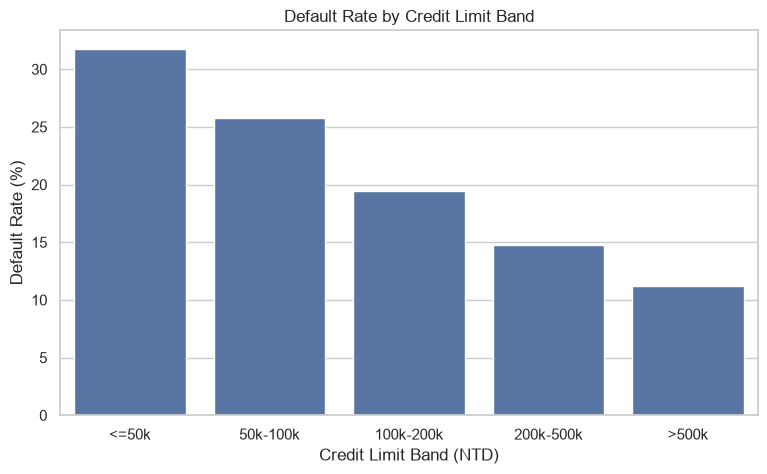

In [12]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=limit_risk,
    x="credit_limit_band",
    y="default_rate"
)

plt.title("Default Rate by Credit Limit Band")
plt.xlabel("Credit Limit Band (NTD)")
plt.ylabel("Default Rate (%)")

plt.show()

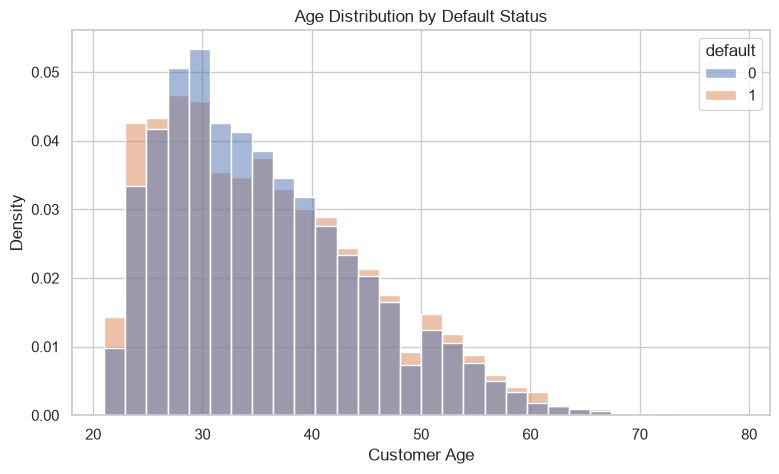

In [13]:
# EDA Part C — Age and default risk
# Step 6 — Analyse age distribution

plt.figure(figsize=(9,5))

sns.histplot(
    data=df,
    x="AGE",
    hue="default",
    bins=30,
    multiple="layer",
    stat="density",
    common_norm=False
)

plt.title("Age Distribution by Default Status")
plt.xlabel("Customer Age")
plt.ylabel("Density")

plt.show()

In [14]:
# Step 7 — Compare default rates across age groups
df["age_group"] = pd.cut(
    df["AGE"],
    bins=[0, 25, 35, 45, 55, np.inf],
    labels=[
        "<=25",
        "26-35",
        "36-45",
        "46-55",
        ">55"
    ]
)

age_risk = (
    df.groupby("age_group", observed=True)
    .agg(
        customers=("default", "size"),
        default_rate=("default", "mean")
    )
    .reset_index()
)

age_risk["default_rate"] *= 100
display(age_risk)

,age_group,customers,default_rate
0,<=25,3871,26.659778
1,26-35,12938,19.825321
2,36-45,8522,21.837597
3,46-55,3825,24.941176
4,>55,844,26.540284


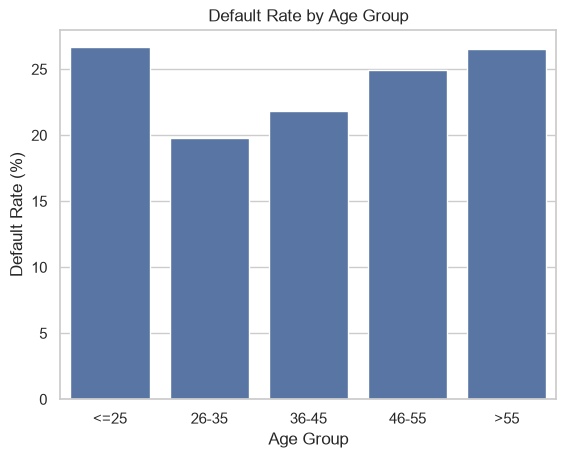

In [16]:
sns.barplot(
    data=age_risk,
    x="age_group",
    y="default_rate"
)

plt.title("Default Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")
plt.show()

In [18]:
# EDA Part D — Repayment behaviour
pay_risk=(
    df.groupby("PAY_1")
    .agg(
        customers=("default", "size"),
        default_rate=("default", "mean")
    )
    .reset_index()
    .sort_values("PAY_1")
)

pay_risk["default_rate"] *= 100
display(pay_risk)

,PAY_1,customers,default_rate
0,-2,2759,13.229431
1,-1,5686,16.778051
2,0,14737,12.811291
3,1,3688,33.947939
4,2,2667,69.141357
5,3,322,75.776398
6,4,76,68.421053
7,5,26,50.000000
8,6,11,54.545455
9,7,9,77.777778


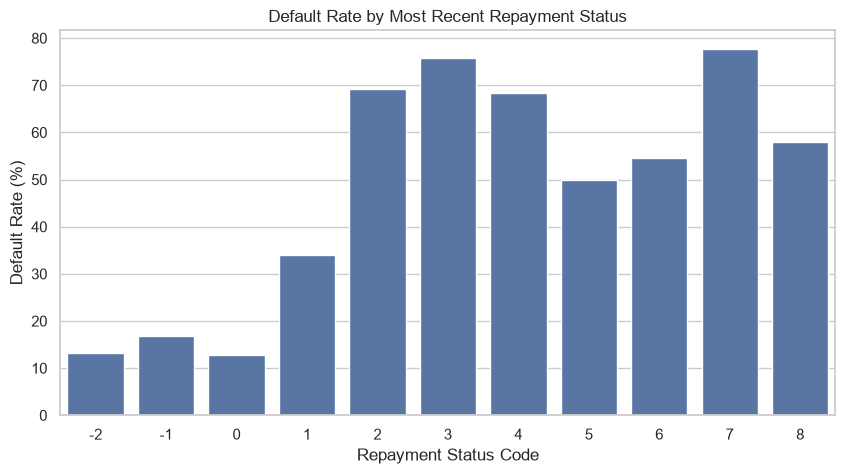

In [21]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=pay_risk,
    x="PAY_1",
    y="default_rate"
)

plt.title("Default Rate by Most Recent Repayment Status")
plt.xlabel("Repayment Status Code")
plt.ylabel("Default Rate (%)")

plt.show()

default,0,1
PAY_1,-0.211222,0.668174
PAY_2,-0.301917,0.458258
PAY_3,-0.316256,0.362116
PAY_4,-0.355633,0.254521
PAY_5,-0.389488,0.167872
PAY_6,-0.405624,0.112116


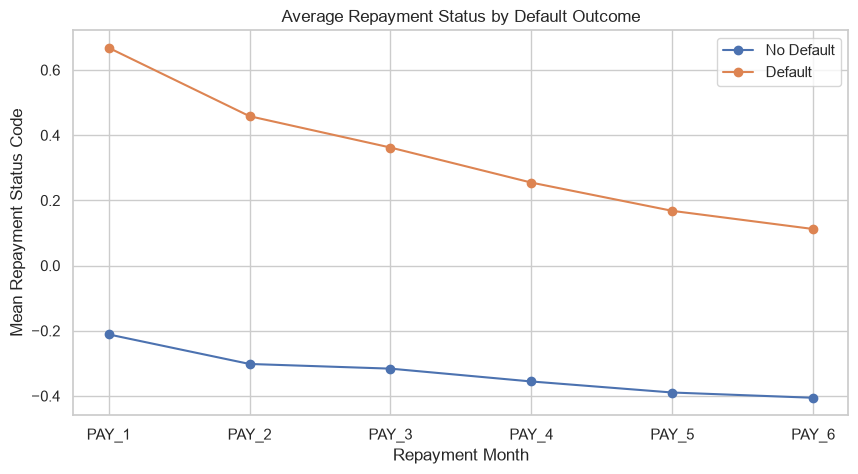

In [22]:
# Step 9 — Analyse historical repayment patterns

pay_cols = [
    "PAY_1", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

pay_summary = df.groupby("default")[pay_cols].mean().T

display(pay_summary)

pay_summary.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Average Repayment Status by Default Outcome")
plt.xlabel("Repayment Month")
plt.ylabel("Mean Repayment Status Code")
plt.legend(["No Default", "Default"])
plt.show()


In [27]:
# EDA Part E — Billing and payment behaviour
# Now we'll investigate whether customers who repay smaller amounts relative to 
# their bills tend to have higher default rates.

# Step 10 — Compare billing and payment amounts
bill_payment_summary = df.groupby("default")[
    ["BILL_AMT1", "PAY_AMT1"]
].agg(["mean", "median"]).round(2)

display(bill_payment_summary)

BILL_AMT1          PAY_AMT1        
             mean   median     mean  median
default                                    
0        51994.23  23119.5  6307.34  2459.5
1        48509.16  20185.0  3397.04  1636.0

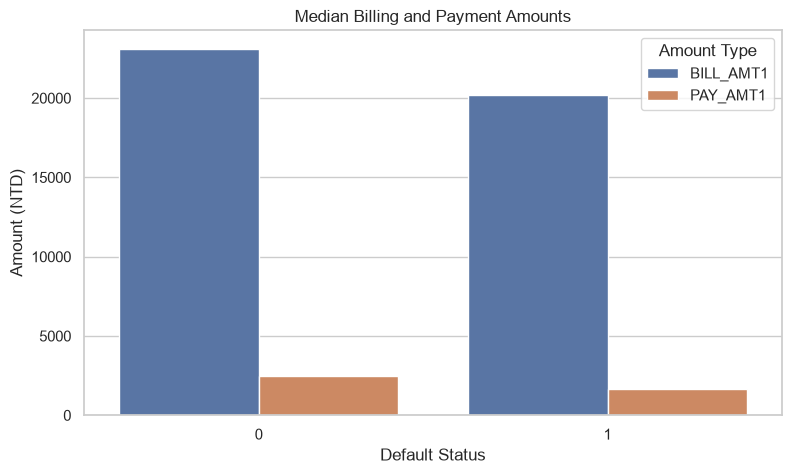

In [29]:
# Create a comparison chart using median values:

plot_data = (
    df.groupby("default")[["BILL_AMT1", "PAY_AMT1"]]
      .median()
      .reset_index()
      .melt(
          id_vars="default",
          var_name="Amount Type",
          value_name="Median Amount"
      )
)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=plot_data,
    x="default",
    y="Median Amount",
    hue="Amount Type"
)

plt.title("Median Billing and Payment Amounts")
plt.xlabel("Default Status")
plt.ylabel("Amount (NTD)")
plt.show()


In [30]:
# Step 11 — Create a payment-to-bill ratio for EDA

df["payment_bill_ratio"] = np.where(
    df["BILL_AMT1"] > 0,
    df["PAY_AMT1"] / df["BILL_AMT1"],
    np.nan
)

print(df["payment_bill_ratio"].describe())

print(
    "Missing or undefined ratios:",
    df["payment_bill_ratio"].isna().sum()
)


count    27402.000000
mean         1.776075
std         76.574498
min          0.000000
25%          0.037448
50%          0.061100
75%          0.273950
max      11453.666667
Name: payment_bill_ratio, dtype: float64
Missing or undefined ratios: 2598


In [31]:

df["payment_ratio_group"] = pd.cut(
    df["payment_bill_ratio"],
    bins=[-np.inf, 0, 0.25, 0.75, 1, np.inf],
    labels=[
        "No payment",
        "0–25%",
        "25–75%",
        "75–100%",
        "Above 100%"
    ]
)

ratio_risk = (
    df.groupby("payment_ratio_group", observed=True)
      .agg(
          customers=("default", "size"),
          default_rate=("default", "mean")
      )
      .reset_index()
)

ratio_risk["default_rate"] *= 100
display(ratio_risk)


,payment_ratio_group,customers,default_rate
0,No payment,3495,39.771102
1,0–25%,16823,20.852404
2,25–75%,2545,15.834971
3,75–100%,1339,18.670650
4,Above 100%,3200,13.812500


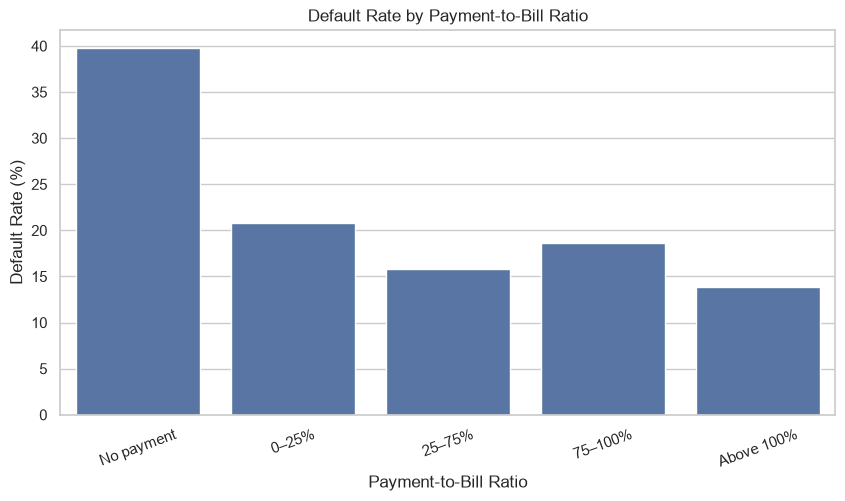

In [32]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=ratio_risk,
    x="payment_ratio_group",
    y="default_rate"
)

plt.title("Default Rate by Payment-to-Bill Ratio")
plt.xlabel("Payment-to-Bill Ratio")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=20)
plt.show()


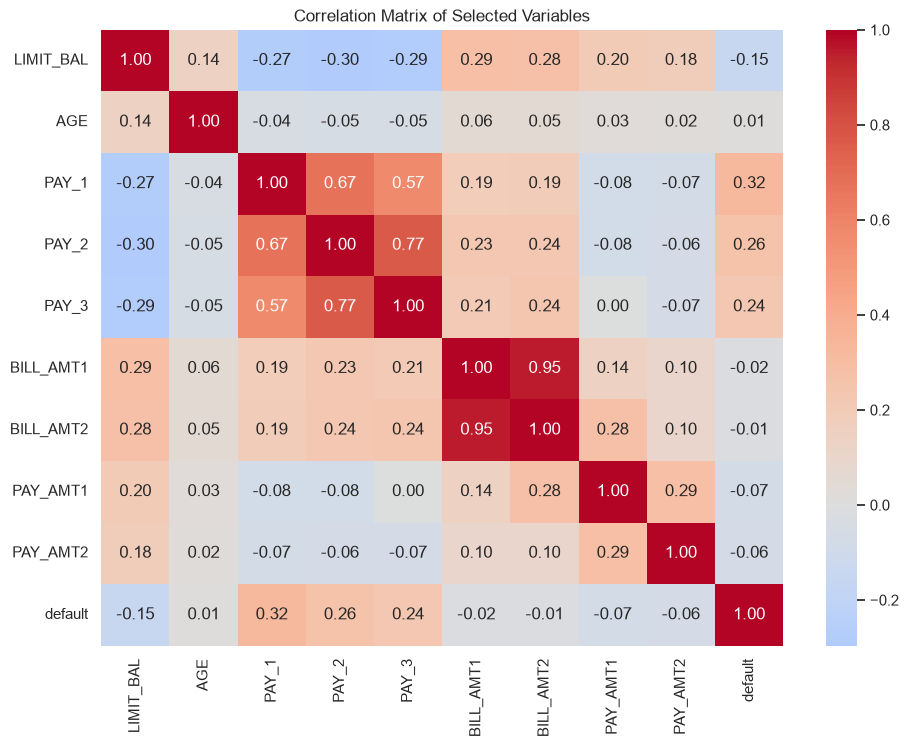

In [33]:
# EDA Part F — Feature relationships
# Step 12 — Correlation heatmap
# A correlation heatmap can help identify relationships among numerical features and the default target.
selected_features = [
    "LIMIT_BAL", "AGE",
    "PAY_1", "PAY_2", "PAY_3",
    "BILL_AMT1", "BILL_AMT2",
    "PAY_AMT1", "PAY_AMT2",
    "default"
]

corr = df[selected_features].corr()
plt.figure(figsize=(11,8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Matrix of Selected Variables")
plt.show()

# How to interpret it:
# - Positive correlation means two variables tend to increase together.
# - Negative correlation means one tends to decrease as the other increases.
# - Correlation close to zero indicates little linear association.

,months_with_delay,customers,default_rate
0,0,19931,11.710401
1,1,4426,29.823769
2,2,1899,38.757241
3,3,1154,50.866551
4,4,951,57.308097
5,5,298,57.382550
6,6,1341,70.320656


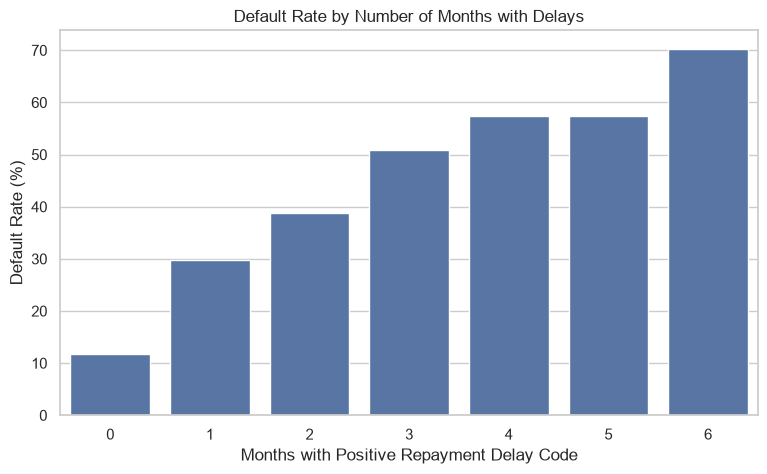

In [34]:
# Step 13 — Create a more meaningful repayment feature

pay_cols = [
    "PAY_1", "PAY_2", "PAY_3",
    "PAY_4", "PAY_5", "PAY_6"
]

df["months_with_delay"] = (
    df[pay_cols] > 0
).sum(axis=1)

delay_risk = (
    df.groupby("months_with_delay")
      .agg(
          customers=("default", "size"),
          default_rate=("default", "mean")
      )
      .reset_index()
)

delay_risk["default_rate"] *= 100

display(delay_risk)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=delay_risk,
    x="months_with_delay",
    y="default_rate"
)

plt.title("Default Rate by Number of Months with Delays")
plt.xlabel("Months with Positive Repayment Delay Code")
plt.ylabel("Default Rate (%)")
plt.show()

### Step 14 — Create your SQL database

In [35]:
import sqlite3
from pathlib import Path

In [37]:
Path("../data/processed").mkdir(
    parents=True,
    exist_ok=True
)

conn = sqlite3.connect(
    "../data/processed/credit_risk.db"
)

# Export the cleaned source columns.
source_df = pd.read_csv("../data/processed/credit_card_cleaned.csv")

source_df.to_sql(
    "credit_customers",
    conn,
    if_exists="replace",
    index=False
)
print("Database created successfully")

Database created successfully


In [42]:
# Query 1 — Overall default rate
query_1 = """
SELECT
    COUNT(*) AS total_customers,
    SUM("default") AS total_defaults,
    ROUND(100.0 * AVG("default"), 2) AS default_rate_pct
FROM credit_customers;
"""

# Query 2 — Default rate by credit limit band
query_2 = """ 
WITH credit_segments AS (
    SELECT
        CASE
            WHEN LIMIT_BAL <= 50000 THEN '1. <=50k'
            WHEN LIMIT_BAL <= 100000 THEN '2. 50k-100k'
            WHEN LIMIT_BAL <= 200000 THEN '3. 100k-200k'
            WHEN LIMIT_BAL <= 500000 THEN '4. 200k-500k'
            ELSE '5. >500k'
        END AS credit_segment,
        "default"
    FROM credit_customers
)
SELECT
    credit_segment,
    COUNT(*) AS customers,
    ROUND(AVG("default") * 100, 2) AS default_rate_pct
FROM credit_segments
GROUP BY credit_segment
ORDER BY credit_segment;
"""
# Business question: Which credit limit segments have higher observed default rates?

# Query 3 — Repayment delay and default
query_3 = """
SELECT
    PAY_1 AS repayment_status,
    COUNT(*) AS customers,
    SUM("default") AS defaults,
    ROUND(AVG("default") * 100, 2) AS default_rate_pct
FROM credit_customers
GROUP BY PAY_1
ORDER BY PAY_1;
"""
#Business question: How does the most recent repayment status relate to default?

# Query 4 — Multiple months with repayment delays

query_4 = """WITH delay_features AS (
    SELECT
        "default",
        (CASE WHEN PAY_1 > 0 THEN 1 ELSE 0 END +
         CASE WHEN PAY_2 > 0 THEN 1 ELSE 0 END +
         CASE WHEN PAY_3 > 0 THEN 1 ELSE 0 END +
         CASE WHEN PAY_4 > 0 THEN 1 ELSE 0 END +
         CASE WHEN PAY_5 > 0 THEN 1 ELSE 0 END +
         CASE WHEN PAY_6 > 0 THEN 1 ELSE 0 END
        ) AS months_with_delay
    FROM credit_customers
)
SELECT
    months_with_delay,
    COUNT(*) AS customers,
    ROUND(AVG("default") * 100, 2) AS default_rate_pct
FROM delay_features
GROUP BY months_with_delay
ORDER BY months_with_delay;
"""

# Step 15 — Run SQL directly from Python
sql_result_1 = pd.read_sql_query(query_1, conn)
sql_result_2 = pd.read_sql_query(query_2, conn)
sql_result_3 = pd.read_sql_query(query_3, conn)
sql_result_4 = pd.read_sql_query(query_4, conn)
display(sql_result_1)
display(sql_result_2)
display(sql_result_3)
display(sql_result_4)

,total_customers,total_defaults,default_rate_pct
0,30000,6636,22.12


,credit_segment,customers,default_rate_pct
0,1. <=50k,7676,31.79
1,2. 50k-100k,4822,25.80
2,3. 100k-200k,7880,19.48
3,4. 200k-500k,9416,14.80
4,5. >500k,206,11.17


,repayment_status,customers,defaults,default_rate_pct
0,-2,2759,365,13.23
1,-1,5686,954,16.78
2,0,14737,1888,12.81
3,1,3688,1252,33.95
4,2,2667,1844,69.14
5,3,322,244,75.78
6,4,76,52,68.42
7,5,26,13,50.00
8,6,11,6,54.55
9,7,9,7,77.78


,months_with_delay,customers,default_rate_pct
0,0,19931,11.71
1,1,4426,29.82
2,2,1899,38.76
3,3,1154,50.87
4,4,951,57.31
5,5,298,57.38
6,6,1341,70.32
